# 06 — Evaluation: metrics beyond R², and where the model is accurate

**Week 8:** compute metrics beyond R² (MAPE and MdAPE), compare every model built so far on the same April 2026 test set, and summarise insights (which price bands, counties and kinds of homes the model values well or badly).

No model is refitted here. Every number comes from the April test predictions saved in Weeks 4–7 (`results/week6_test_predictions.csv`, `results/week7_test_predictions.csv`), so this notebook runs in under a minute.

**Deliverables:** this notebook and `results/metrics_summary.csv` (plus `results/metrics_by_segment.csv`).

## 1. Setup and load the saved predictions

In [1]:
import sys, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import sklearn

ROOT = next(p for p in [Path("."), Path("..")] if (p / "processed").exists()).resolve()
sys.path.insert(0, str(ROOT / "py"))
import preprocessing as pp
import modeling as mdl
import feature_engineering as fe

PROC, RES_DIR, FIG_DIR = ROOT / "processed", ROOT / "results", ROOT / "figures" / "06_evaluation"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
BLUE, ORANGE, GREEN, GREY, PURPLE, RED = "#2a78d6", "#eb6834", "#2e9e6a", "#8a8984", "#7a5cc7", "#c8453a"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cfca", "grid.color": "#ecebe7",
                                     "axes.titleweight": "bold", "figure.dpi": 110})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)
rng = np.random.default_rng(pp.SEED)
cfg = json.loads((PROC / "preprocessing_config.json").read_text())
TEST_MONTH = cfg["test_month"]
run7 = json.loads((RES_DIR / "week7_run_info.json").read_text())
print(f"python {platform.python_version()} | scikit-learn {sklearn.__version__} | test = {TEST_MONTH}")

python 3.13.18 | scikit-learn 1.7.2 | test = 2026-04


In [2]:
clean = fe.add_school_features(mdl.load_clean(PROC / "sold_sfr_clean.csv"),
                               pd.read_csv(PROC / "school_district_join.csv", dtype={"ListingKey": str}))
test = clean[clean.split == "test"].reset_index(drop=True)
p6 = pd.read_csv(RES_DIR / "week6_test_predictions.csv", dtype={"ListingKey": str})
p7 = pd.read_csv(RES_DIR / "week7_test_predictions.csv", dtype={"ListingKey": str})
assert (p6.ListingKey.values == test.ListingKey.values).all() and (p7.ListingKey.values == test.ListingKey.values).all()
y = test.ClosePrice.to_numpy()

results = pd.read_csv(RES_DIR / "model_results.csv").set_index("model")
blend_label = next(m for m in results.index if m.startswith("Week 7: Blend"))
# short name -> (row in model_results.csv, April predictions in dollars)
MODELS = {
    "Comp median price": ("Reference: comp median price (no model)", np.exp(test.comp_log_price.to_numpy())),
    "Comp $/sqft × size": ("Reference: comp price/sq ft x living area (no model)", np.exp(test.comp_log_ppsf.to_numpy()) * test.LivingArea.to_numpy()),
    "Linear Regression": ("Baseline: Linear Regression", p6.pred_linear_regression_A.to_numpy()),
    "Linear Regression (D)": ("Week 6: Linear Regression (D. New (all))", p6.pred_linear_regression_D.to_numpy()),
    "Decision Tree": ("Week 5: Decision Tree", p6.pred_decision_tree_A.to_numpy()),
    "Random Forest": ("Week 5: Random Forest", p6.pred_random_forest_A.to_numpy()),
    "Random Forest (C)": ("Week 6: Random Forest (C. + school district)", p6.pred_random_forest_C.to_numpy()),
    "XGBoost (C)": ("Week 7: XGBoost (C)", p7.pred_xgboost.to_numpy()),
    "LightGBM (C)": ("Week 7: LightGBM (C)", p7.pred_lightgbm.to_numpy()),
    "Blend (C)": (blend_label, p7.pred_blend.to_numpy()),
}
STAGE = {"Comp median price": "Reference", "Comp $/sqft × size": "Reference", "Linear Regression": "Week 4",
         "Linear Regression (D)": "Week 6", "Decision Tree": "Week 5", "Random Forest": "Week 5",
         "Random Forest (C)": "Week 6", "XGBoost (C)": "Week 7", "LightGBM (C)": "Week 7", "Blend (C)": "Week 7"}

# Check: recomputed April metrics match what each week saved
for k, (row, p) in MODELS.items():
    got = mdl.full_metrics(y, p)
    for metric in ["MdAPE", "MAPE", "R2"]:
        assert np.isclose(got[metric], results.loc[row, metric], rtol=1e-3), (k, metric, got[metric], results.loc[row, metric])
print(f"{len(MODELS)} models, {len(y):,} April test homes; all match results/model_results.csv")
print("Blend:", blend_label, "| weights", run7["blend_weights_log_scale"])

10 models, 12,175 April test homes; all match results/model_results.csv
Blend: Week 7: Blend 0.5/0.5/0.0 LGBM/XGB/RF (C) | weights {'LightGBM': 0.5, 'XGBoost': 0.5, 'Random Forest': 0.0}


## 2. The metrics

For each home, the error is $e = (\hat{y} - y) / y$ (prediction minus sale price, as a share of the sale price) and the absolute percentage error is $|e|$.

| Metric | Definition | What it tells you |
|---|---|---|
| **R²** | $1 - \sum(\hat y - y)^2 / \sum(y - \bar y)^2$ in dollars | share of price variance explained; dominated by expensive homes (a $300K miss on a $5M home counts 100× a $30K miss on a $500K home) |
| R² (log) | the same on log prices | variance explained in *percentage* terms; every home counts about equally |
| **MAPE** | mean of $\lvert e\rvert$ | average % miss; pulled up by a small number of very large misses |
| **MdAPE** | median of $\lvert e\rvert$ | the typical % miss: half the homes are valued closer than this. The AVM industry's headline metric (best-practices doc, section 08) |
| Within 5 / 10 / 20% | share of homes with $\lvert e\rvert$ ≤ 5 / 10 / 20% | "hit rate"; within 10% is the common AVM benchmark |
| Median bias | median of $e$ | systematic over- (+) or under- (−) valuation |
| MAE, RMSE, MedAE | dollar errors | size of misses in dollars |

95% confidence intervals for MdAPE and MAPE come from 2,000 bootstrap resamples of the April test homes.

## 3. Overall metrics for every model (`metrics_summary.csv`)

In [3]:
B = 2000
idx = rng.integers(0, len(y), size=(B, len(y)))       # same resamples for every model (paired)
ape = {k: np.abs(p - y) / y for k, (_, p) in MODELS.items()}
rows = []
for k, (row, p) in MODELS.items():
    a = ape[k][idx]
    md_b, mp_b = np.median(a, axis=1) * 100, a.mean(axis=1) * 100
    rows.append({"model": k, "stage": STAGE[k], "results_row": row, **mdl.full_metrics(y, p),
                 "MdAPE_ci_low": np.percentile(md_b, 2.5), "MdAPE_ci_high": np.percentile(md_b, 97.5),
                 "MAPE_ci_low": np.percentile(mp_b, 2.5), "MAPE_ci_high": np.percentile(mp_b, 97.5),
                 "validation_MdAPE": results.loc[row, "validation_MdAPE_mean"]})
summary = pd.DataFrame(rows).set_index("model")
summary["MAPE_to_MdAPE"] = summary.MAPE / summary.MdAPE
cols = ["stage", "n", "R2", "R2_log", "MAPE", "MAPE_ci_low", "MAPE_ci_high", "MdAPE", "MdAPE_ci_low", "MdAPE_ci_high",
        "MAPE_to_MdAPE", "MAE", "RMSE", "MedAE", "within_5pct", "within_10pct", "within_20pct", "median_bias_pct",
        "validation_MdAPE", "results_row"]
summary = summary[cols]
summary.round(4).to_csv(RES_DIR / "metrics_summary.csv")

show = summary.copy()
show["MdAPE (95% CI)"] = [f"{r.MdAPE:.2f}% ({r.MdAPE_ci_low:.2f}–{r.MdAPE_ci_high:.2f})" for r in summary.itertuples()]
show["MAPE (95% CI)"] = [f"{r.MAPE:.2f}% ({r.MAPE_ci_low:.2f}–{r.MAPE_ci_high:.2f})" for r in summary.itertuples()]
fmt = {"R2": "{:.4f}", "R2_log": "{:.4f}", "MAE": "${:,.0f}", "RMSE": "${:,.0f}", "within_5pct": "{:.1f}%",
       "within_10pct": "{:.1f}%", "within_20pct": "{:.1f}%", "median_bias_pct": "{:+.2f}%", "validation_MdAPE": "{:.2f}%"}
for c, f in fmt.items(): show[c] = show[c].map(lambda v: "" if pd.isna(v) else f.format(v))
show[["stage", "R2", "R2_log", "MAPE (95% CI)", "MdAPE (95% CI)", "within_5pct", "within_10pct", "within_20pct",
      "median_bias_pct", "MAE", "RMSE", "validation_MdAPE"]].rename(columns={
    "R2": "R²", "R2_log": "R² (log)", "within_5pct": "≤5%", "within_10pct": "≤10%", "within_20pct": "≤20%",
    "median_bias_pct": "bias", "validation_MdAPE": "val MdAPE"})

,stage,R²,R² (log),MAPE (95% CI),MdAPE (95% CI),≤5%,≤10%,≤20%,bias,MAE,RMSE,val MdAPE
model,,,,,,,,,,,,
Comp median price,Reference,0.7066,0.8353,17.54% (17.21–17.89),12.03% (11.69–12.32),24.2%,43.8%,69.2%,-1.74%,"$251,237","$518,554",
Comp $/sqft × size,Reference,0.8606,0.8842,16.58% (16.30–16.86),12.71% (12.45–13.00),20.9%,40.5%,69.9%,-1.33%,"$202,409","$357,368",
Linear Regression,Week 4,0.8886,0.9322,12.02% (11.79–12.25),8.63% (8.43–8.80),31.1%,56.2%,83.4%,-0.61%,"$161,003","$319,549",8.75%
Linear Regression (D),Week 6,0.8887,0.9329,11.93% (11.70–12.15),8.51% (8.31–8.71),31.6%,56.4%,83.5%,-0.44%,"$160,230","$319,358",8.65%
Decision Tree,Week 5,0.8857,0.9239,12.64% (12.41–12.89),8.98% (8.74–9.20),29.6%,54.0%,81.2%,-1.68%,"$168,812","$323,704",9.08%
Random Forest,Week 5,0.9060,0.9401,10.95% (10.73–11.17),7.58% (7.43–7.75),35.6%,60.9%,85.6%,-1.41%,"$148,865","$293,508",7.51%
Random Forest (C),Week 6,0.9063,0.9406,10.89% (10.67–11.11),7.53% (7.32–7.70),35.8%,61.2%,85.6%,-1.42%,"$148,440","$293,044",7.48%
XGBoost (C),Week 7,0.9188,0.9480,10.37% (10.16–10.57),7.16% (6.99–7.34),37.0%,63.2%,87.2%,-0.58%,"$139,359","$272,858",7.07%
LightGBM (C),Week 7,0.9229,0.9496,10.26% (10.06–10.45),7.12% (6.96–7.27),37.1%,63.5%,87.5%,-0.57%,"$137,212","$265,817",7.05%


Best model, chosen on validation MdAPE (not on April): Blend (C)


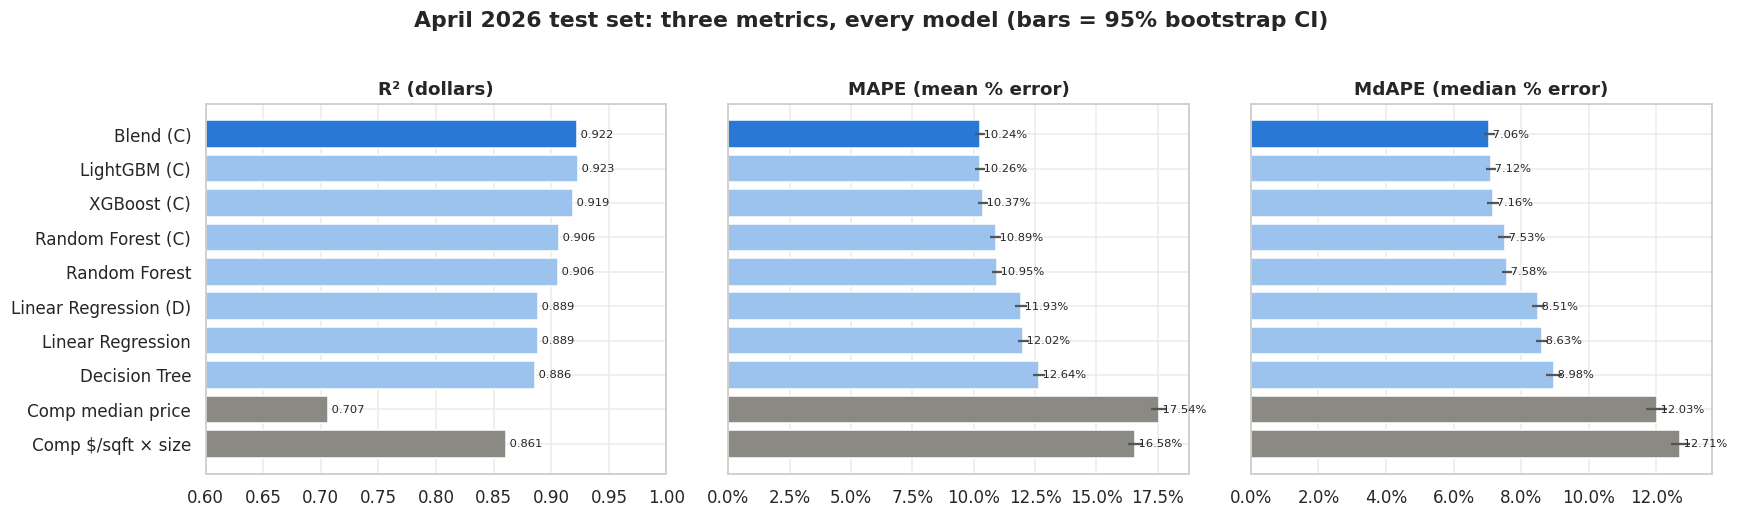

In [4]:
BEST = summary.drop(index=[k for k in summary.index if STAGE[k] == "Reference"]).validation_MdAPE.idxmin()
print("Best model, chosen on validation MdAPE (not on April):", BEST)
order = summary.sort_values("MdAPE", ascending=False).index
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
colr = [BLUE if k == BEST else (GREY if STAGE[k] == "Reference" else "#9cc3ee") for k in order]
s = summary.loc[order]
ax[0].barh(order, s.R2, color=colr); ax[0].set(title="R² (dollars)", xlim=(0.6, 1))
ax[1].barh(order, s.MAPE, color=colr, xerr=[s.MAPE - s.MAPE_ci_low, s.MAPE_ci_high - s.MAPE], ecolor="#555")
ax[1].set_title("MAPE (mean % error)"); ax[1].xaxis.set_major_formatter(mtick.PercentFormatter())
ax[2].barh(order, s.MdAPE, color=colr, xerr=[s.MdAPE - s.MdAPE_ci_low, s.MdAPE_ci_high - s.MdAPE], ecolor="#555")
ax[2].set_title("MdAPE (median % error)"); ax[2].xaxis.set_major_formatter(mtick.PercentFormatter())
for a, c_ in zip(ax, ["R2", "MAPE", "MdAPE"]):
    for i, v in enumerate(s[c_]): a.text(v, i, f" {v:.3f}" if c_ == "R2" else f" {v:.2f}%", va="center", fontsize=7.5)
fig.suptitle("April 2026 test set: three metrics, every model (bars = 95% bootstrap CI)", fontweight="bold", y=1.02)
fig.tight_layout(); save(fig, "metrics_by_model"); plt.show()

**Are the differences real?** Paired bootstrap of the MdAPE difference (same resampled homes for both models). If the 95% interval excludes 0, the difference is unlikely to be a fluke of which homes sold in April.

In [5]:
def paired(a, b):
    d = (np.median(ape[a][idx], axis=1) - np.median(ape[b][idx], axis=1)) * 100
    return {"comparison": f"{a} − {b}", "MdAPE_diff": (np.median(ape[a]) - np.median(ape[b])) * 100,
            "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5), "P(diff < 0)": (d < 0).mean()}
pairs = [(BEST, "Random Forest (C)"), (BEST, "Linear Regression"), (BEST, "Comp $/sqft × size"),
         ("LightGBM (C)", "XGBoost (C)"), ("Random Forest (C)", "Random Forest"), ("Random Forest", "Linear Regression")]
pairs = [p for p in dict.fromkeys(pairs) if p[0] != p[1]]
paired_tab = pd.DataFrame([paired(a, b) for a, b in pairs]).set_index("comparison")
paired_tab.round(3)

,MdAPE_diff,ci_low,ci_high,P(diff < 0)
comparison,,,,
Blend (C) − Random Forest (C),-0.471,-0.616,-0.313,1.000
Blend (C) − Linear Regression,-1.566,-1.734,-1.381,1.000
Blend (C) − Comp $/sqft × size,-5.650,-5.954,-5.367,1.000
LightGBM (C) − XGBoost (C),-0.043,-0.159,0.068,0.775
Random Forest (C) − Random Forest,-0.049,-0.167,0.031,0.909
Random Forest − Linear Regression,-1.046,-1.189,-0.863,1.000


## 4. Why MAPE is so much larger than MdAPE

For every model, MAPE is about 1.4–1.5× MdAPE. The error distribution has a long right tail: most homes are valued within a few percent, and a small share are missed by 30–100%+ (unusual homes, data-entry errors in the sale record, non-market sales that passed cleaning). The mean is pulled up by that tail; the median is not.

Blend (C): MAPE 10.24% | MdAPE 7.06% | 90th pct APE 22.1% | 99th pct 52.1%


,share of homes,APE threshold,share of total absolute % error,MAPE without them
0,worst 1%,52.10,7.34,9.59
1,worst 5%,30.18,21.88,8.42
2,worst 10%,22.13,34.43,7.46


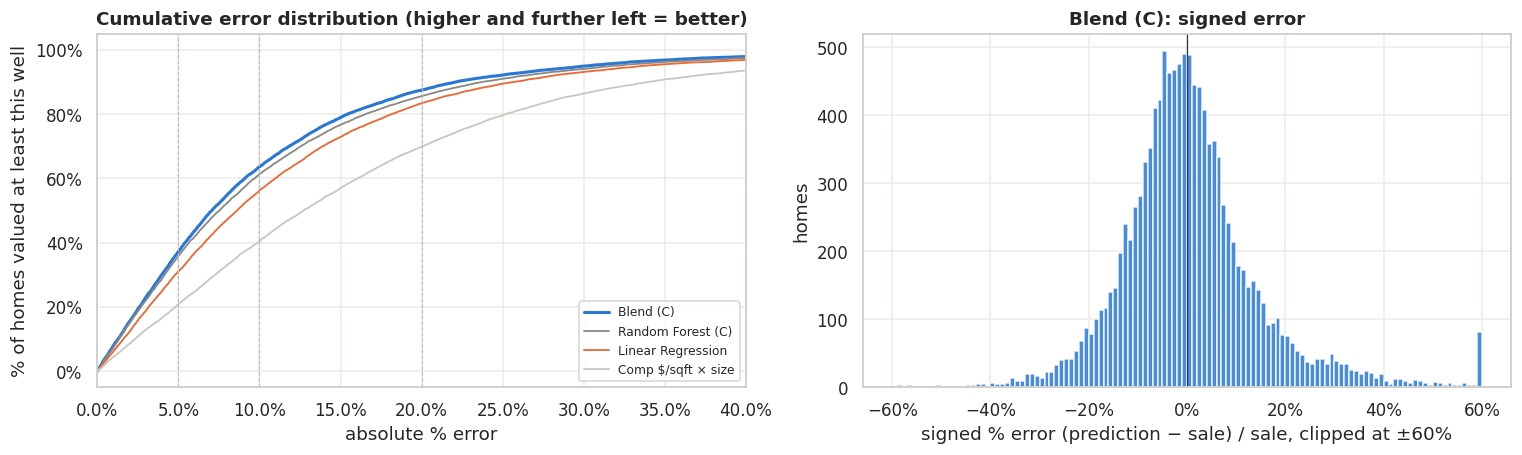

In [6]:
a_best = ape[BEST] * 100
srt = np.sort(a_best)[::-1]
tail = pd.DataFrame({
    "share of homes": ["worst 1%", "worst 5%", "worst 10%"],
    "APE threshold": [np.percentile(a_best, 99), np.percentile(a_best, 95), np.percentile(a_best, 90)],
    "share of total absolute % error": [srt[: int(len(srt) * f)].sum() / srt.sum() * 100 for f in (0.01, 0.05, 0.10)],
    "MAPE without them": [srt[int(len(srt) * f):].mean() for f in (0.01, 0.05, 0.10)],
})
print(f"{BEST}: MAPE {a_best.mean():.2f}% | MdAPE {np.median(a_best):.2f}% | 90th pct APE {np.percentile(a_best, 90):.1f}% | 99th pct {np.percentile(a_best, 99):.1f}%")
display(tail.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
for k, c_ in dict.fromkeys([(BEST, BLUE), ("Random Forest (C)", GREY), ("Linear Regression", ORANGE), ("Comp $/sqft × size", "#c9c7c0")]):
    if k == BEST and c_ != BLUE: continue
    v = np.sort(ape[k] * 100)
    ax[0].plot(v, np.arange(1, len(v) + 1) / len(v) * 100, color=c_, lw=2 if k == BEST else 1.2, label=k)
for x_ in (5, 10, 20): ax[0].axvline(x_, color="#bbb", lw=0.7, ls="--")
ax[0].set(xlim=(0, 40), xlabel="absolute % error", ylabel="% of homes valued at least this well",
          title="Cumulative error distribution (higher and further left = better)")
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].legend(fontsize=8)
err_best = (MODELS[BEST][1] - y) / y * 100
ax[1].hist(np.clip(err_best, -60, 60), bins=120, color=BLUE, alpha=0.85)
ax[1].axvline(0, color="#333", lw=0.8)
ax[1].set(xlabel="signed % error (prediction − sale) / sale, clipped at ±60%", ylabel="homes", title=f"{BEST}: signed error")
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter())
fig.tight_layout(); save(fig, "error_distribution"); plt.show()

**R² in dollars vs log.** Dollar R² is driven by the most expensive homes: the top 10% of April sales by price account for most of the total squared error.

In [7]:
p_best = MODELS[BEST][1]
sq = (p_best - y) ** 2
top10 = y >= np.percentile(y, 90)
print(f"{BEST}: top 10% of homes by price (≥ ${np.percentile(y, 90):,.0f}) = {sq[top10].sum() / sq.sum():.0%} of the squared dollar error")
print(f"R² (dollars) {summary.loc[BEST, 'R2']:.4f} | R² (log) {summary.loc[BEST, 'R2_log']:.4f} | "
      f"R² on homes under the 90th percentile only: {1 - sq[~top10].sum() / ((y[~top10] - y[~top10].mean()) ** 2).sum():.4f}")

Blend (C): top 10% of homes by price (≥ $2,300,000) = 68% of the squared dollar error
R² (dollars) 0.9220 | R² (log) 0.9494 | R² on homes under the 90th percentile only: 0.8862


## 5. Which price bands perform better?

Two ways to band homes, and they give different pictures:

* **By actual sale price** (what Weeks 4–7 reported). Every model looks biased *upward* on the cheapest homes and *downward* on the most expensive ones. Part of this is mechanical: a home that sold unusually cheaply for what it is lands in the bottom band *because* of its low price, so the model's sensible estimate looks too high (and vice versa at the top). This is regression to the mean, not necessarily a flaw of the model.
* **By predicted price** (what a user of the model actually sees: "the model says $1.2M; how far off is that usually?"). This is the fair way to state accuracy for a band.

In [8]:
def band_table(groups, keys):
    out = []
    for k in keys:
        g = mdl.error_by_group(y, MODELS[k][1], groups)
        g["within_5pct"] = pd.Series((ape[k] <= 0.05)).groupby(np.asarray(groups)).mean().reindex(g.index).values * 100
        out.append(g.assign(model=k))
    return pd.concat(out).reset_index(names="band")

KEYS = list(dict.fromkeys([BEST, "Random Forest (C)", "Linear Regression", "Comp $/sqft × size"]))
act_bands = mdl.price_bands(y, 5)
q_edges = np.quantile(p_best, np.linspace(0, 1, 6))
pred_bands = pd.Series(pd.cut(p_best, q_edges, include_lowest=True,
                       labels=[f"Q{i+1}: ${q_edges[i]/1e3:,.0f}K-${q_edges[i+1]/1e3:,.0f}K" for i in range(5)]))
by_actual, by_pred = band_table(act_bands, KEYS), band_table(pred_bands, [BEST])

t = by_actual[by_actual.model == BEST].set_index("band")[["n", "median_price", "MdAPE", "MAPE", "within_10pct", "median_bias"]]
t2 = by_pred.set_index("band")[["n", "median_price", "MdAPE", "MAPE", "within_10pct", "median_bias"]]
display(pd.concat({f"{BEST}, banded by ACTUAL price": t, f"{BEST}, banded by PREDICTED price": t2}).round(2))

n  median_price  MdAPE   MAPE  within_10pct  median_bias
                                     band                                                                            
Blend (C), banded by ACTUAL price    Q1: $189K-$575K      2461      450000.0   6.40  10.82         65.95         1.56
                                     Q2: $575K-$800K      2464      699000.0   5.46   8.17         73.78        -0.00
                                     Q3: $800K-$1,100K    2480      925000.0   6.41   8.85         69.44        -0.31
                                     Q4: $1,100K-$1,652K  2335     1325000.0   7.99  10.64         59.23        -1.72
                                     Q5: $1,652K-$8,400K  2435     2300000.0  10.15  12.79         49.36        -4.48
Blend (C), banded by PREDICTED price Q1: $207K-$580K      2435      450000.0   6.29   9.50         67.76        -0.48
                                     Q2: $580K-$799K      2435      699990.0   5.37   8.09         74.74        -0.86
                                     Q3: $799K-$1,084K    2435      916000.0   6.59   9.11         68.05        -0.34
                                     Q4: $1,084K-$1,636K  2435     1315000.0   8.28  11.13         57.62        -0.58
                                     Q5: $1,636K-$7,903K  2435     2300000.0   9.99  13.38         50.02        -0.51

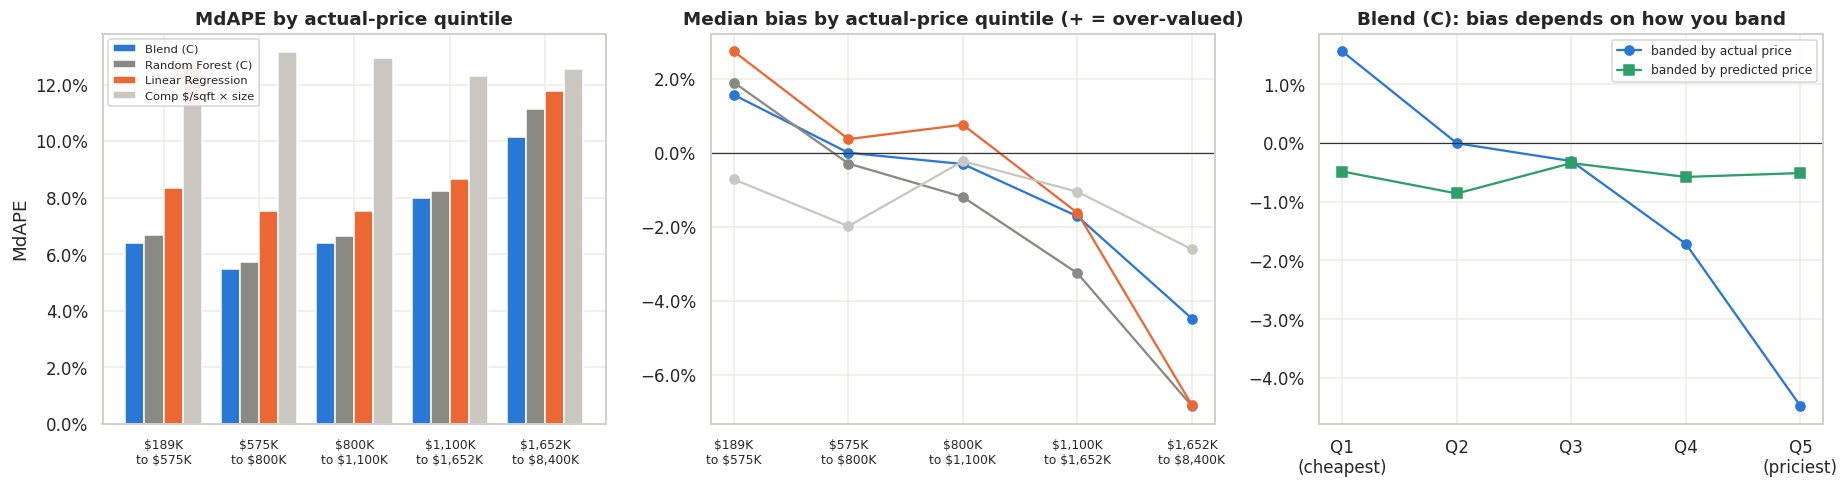

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(5)
for i, (k, c_) in enumerate(zip(KEYS, [BLUE, GREY, ORANGE, "#c9c7c0"])):
    g = by_actual[by_actual.model == k]
    ax[0].bar(x + (i - 1.5) * 0.2, g.MdAPE, 0.2, color=c_, label=k)
    ax[1].plot(x, g.median_bias, marker="o", color=c_, label=k)
lbl = [b.split(": ")[1].replace("-", "\nto ").replace("$", r"\$") for b in act_bands.cat.categories]
for a in ax[:2]: a.set_xticks(x, lbl, fontsize=8)
ax[0].set(title="MdAPE by actual-price quintile", ylabel="MdAPE"); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].legend(fontsize=7.5)
ax[1].axhline(0, color="#333", lw=0.8); ax[1].set(title="Median bias by actual-price quintile (+ = over-valued)")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter())
ax[2].plot(x, by_actual[by_actual.model == BEST].median_bias, marker="o", color=BLUE, label="banded by actual price")
ax[2].plot(x, by_pred.median_bias, marker="s", color=GREEN, label="banded by predicted price")
ax[2].axhline(0, color="#333", lw=0.8); ax[2].set_xticks(x, ["Q1\n(cheapest)", "Q2", "Q3", "Q4", "Q5\n(priciest)"])
ax[2].set(title=f"{BEST}: bias depends on how you band"); ax[2].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[2].legend(fontsize=8)
fig.tight_layout(); save(fig, "price_bands"); plt.show()

Finer view: deciles of actual price for the best model.

In [10]:
b10 = mdl.price_bands(y, 10)
dec = mdl.error_by_group(y, p_best, b10)
dec["within_5pct"] = pd.Series(ape[BEST] <= 0.05).groupby(np.asarray(b10)).mean().reindex(dec.index) * 100
dec.loc[[c_ for c_ in b10.cat.categories if c_ in dec.index]].round(2)

,n,median_price,MdAPE,MAPE,MAE,within_10pct,median_bias,within_5pct
g,,,,,,,,
Q1: $189K-$450K,1250,380000.0,7.23,12.75,43911.82,60.32,3.27,35.52
Q2: $450K-$575K,1211,520000.0,5.67,8.83,45675.60,71.76,0.11,45.09
Q3: $575K-$690K,1194,636500.0,5.47,8.67,54841.91,72.86,0.14,46.15
Q4: $690K-$800K,1270,749900.0,5.46,7.70,57444.96,74.65,-0.22,45.98
Q5: $800K-$910K,1163,855000.0,5.92,8.63,73902.50,71.71,-0.37,43.59
"Q6: $910K-$1,100K",1317,997999.0,6.83,9.04,91151.84,67.43,-0.16,38.27
"Q7: $1,100K-$1,320K",1117,1207500.0,7.96,10.38,126074.66,60.61,-2.04,31.60
"Q8: $1,320K-$1,652K",1218,1475000.0,8.06,10.88,160638.99,57.96,-1.51,33.99
"Q9: $1,652K-$2,300K",1220,1895000.0,9.07,11.73,226137.27,53.44,-2.64,28.03


## 6. Other segments: county, home size, age, and how close the comps are

All for the best model, banded by characteristics known at prediction time (so a user can read off the expected accuracy for a given home).

In [11]:
seg_def = {
    "County": test.CountyOrParish.where(test.CountyOrParish.map(test.CountyOrParish.value_counts()) >= 300, "Other (<300 sales)"),
    "Living area": pd.cut(test.LivingArea, [0, 1000, 1500, 2000, 2500, 3500, np.inf],
                          labels=["<1,000", "1,000-1,500", "1,500-2,000", "2,000-2,500", "2,500-3,500", "3,500+"]),
    "Age (years)": pd.cut(test.age, [-1, 10, 30, 50, 70, np.inf], labels=["0-10", "11-30", "31-50", "51-70", "70+"]),
    "Distance to 10 comps": pd.qcut(np.exp(test.comp_log_dist_km), 5,
                                    labels=["Q1 (closest)", "Q2", "Q3", "Q4", "Q5 (farthest)"]),
    "School district type": test.sd_type.fillna("Unknown"),
}
seg_rows = []
for sname, g in seg_def.items():
    for k in dict.fromkeys([BEST, "Random Forest (C)", "Linear Regression"]):
        e = mdl.error_by_group(y, MODELS[k][1], g.astype(str).replace("nan", "Unknown").to_numpy())
        seg_rows.append(e.assign(segment_type=sname, model=k).reset_index(names="segment"))
for k in KEYS:   # price bands too, so metrics_by_segment.csv holds everything
    seg_rows.append(by_actual[by_actual.model == k].rename(columns={"band": "segment"}).assign(segment_type="Actual price quintile"))
seg_rows.append(by_pred.rename(columns={"band": "segment"}).assign(segment_type="Predicted price quintile"))
segments = pd.concat(seg_rows, ignore_index=True)[["segment_type", "segment", "model", "n", "median_price", "MdAPE", "MAPE", "MAE", "within_10pct", "median_bias"]]
segments.round(3).to_csv(RES_DIR / "metrics_by_segment.csv", index=False)

dist_km = np.exp(test.comp_log_dist_km).groupby(seg_def["Distance to 10 comps"], observed=True).median()
print("Median distance to the 10 comps by quintile (km):", dist_km.round(2).to_dict())
segments[segments.model == BEST].set_index(["segment_type", "segment"]).drop(columns="model").round(2)

Median distance to the 10 comps by quintile (km): {'Q1 (closest)': 0.21, 'Q2': 0.29, 'Q3': 0.36, 'Q4': 0.45, 'Q5 (farthest)': 0.74}


n  median_price  MdAPE   MAPE        MAE  within_10pct  median_bias
segment_type             segment                                                                                    
County                   Alameda               582     1323000.0  10.04  13.35  193953.29         49.83        -2.83
                         Contra Costa          574      902842.5   7.06   9.71  122368.69         65.51        -0.60
                         Los Angeles          3009     1011000.0   7.82  10.97  163730.85         60.42        -0.30
                         Orange               1165     1430000.0   6.75   9.13  172293.95         66.01        -1.10
                         Other (<300 sales)   1523      639000.0   7.33  11.09  124882.77         61.46        -0.88
                         Riverside            1875      639000.0   5.67   9.01   86706.43         70.77        -0.07
                         San Bernardino       1219      555000.0   5.79   8.76   53104.37         70.55        -0.06
                         San Diego            1421     1095000.0   7.69  10.28  155197.64         61.08        -0.85
                         Santa Clara           388     1895000.0   7.42  10.84  237508.32         63.14        -0.80
                         Ventura               419      999009.0   7.32  10.63  155169.96         61.81        -0.84
Living area              1,000-1,500          3138      749000.0   6.68   9.51   75514.10         67.75        -1.41
                         1,500-2,000          3296      868500.0   6.38   9.31   97881.28         67.51        -0.40
                         2,000-2,500          2188     1100000.0   6.80   9.94  137445.26         64.12         0.18
                         2,500-3,500          2032     1420000.0   7.84  11.03  202383.19         59.94        -0.07
                         3,500+                834     2700000.0  10.39  13.74  422353.49         48.56        -1.07
                         <1,000                687      599000.0   8.87  12.45   69758.24         54.00        -1.02
Age (years)              0-10                 1113      764000.0   4.99   7.28  117874.63         77.99         0.10
                         11-30                2208      860000.0   5.88   8.55  129902.52         71.69         0.22
                         31-50                2915      875000.0   6.68   9.84  125670.68         65.28        -0.42
                         51-70                2977     1030000.0   7.63  10.64  137670.84         61.40        -1.10
                         70+                  2956      925000.0   9.23  12.61  161188.37         52.91        -1.67
                         Unknown                 6     1035000.0  12.46  12.61  175228.50         33.33        -7.02
Distance to 10 comps     Q1 (closest)         2435      837100.0   6.06   8.97  107801.72         67.84        -0.28
                         Q2                   2435      925000.0   6.90   9.50  125023.90         65.67        -0.96
                         Q3                   2435      945000.0   6.76   9.82  134700.43         65.17        -0.26
                         Q4                   2435      988000.0   7.23  10.48  154101.28         63.94        -0.65
                         Q5 (farthest)        2435      860000.0   8.51  12.44  164910.49         55.56        -0.74
School district type     Elementary + High    2998      860000.0   6.07   8.75  116931.71         70.18        -0.71
                         Unified              9177      935000.0   7.46  10.73  143964.07         61.50        -0.51
Actual price quintile    Q1: $189K-$575K      2461      450000.0   6.40  10.82   44779.74         65.95         1.56
                         Q2: $575K-$800K      2464      699000.0   5.46   8.17   56183.58         73.78        -0.00
                         Q3: $800K-$1,100K    2480      925000.0   6.41   8.85   83062.74         69.44        -0.31
                         Q4: $1,100K-$1,652K  2335     1325000.0   7.99

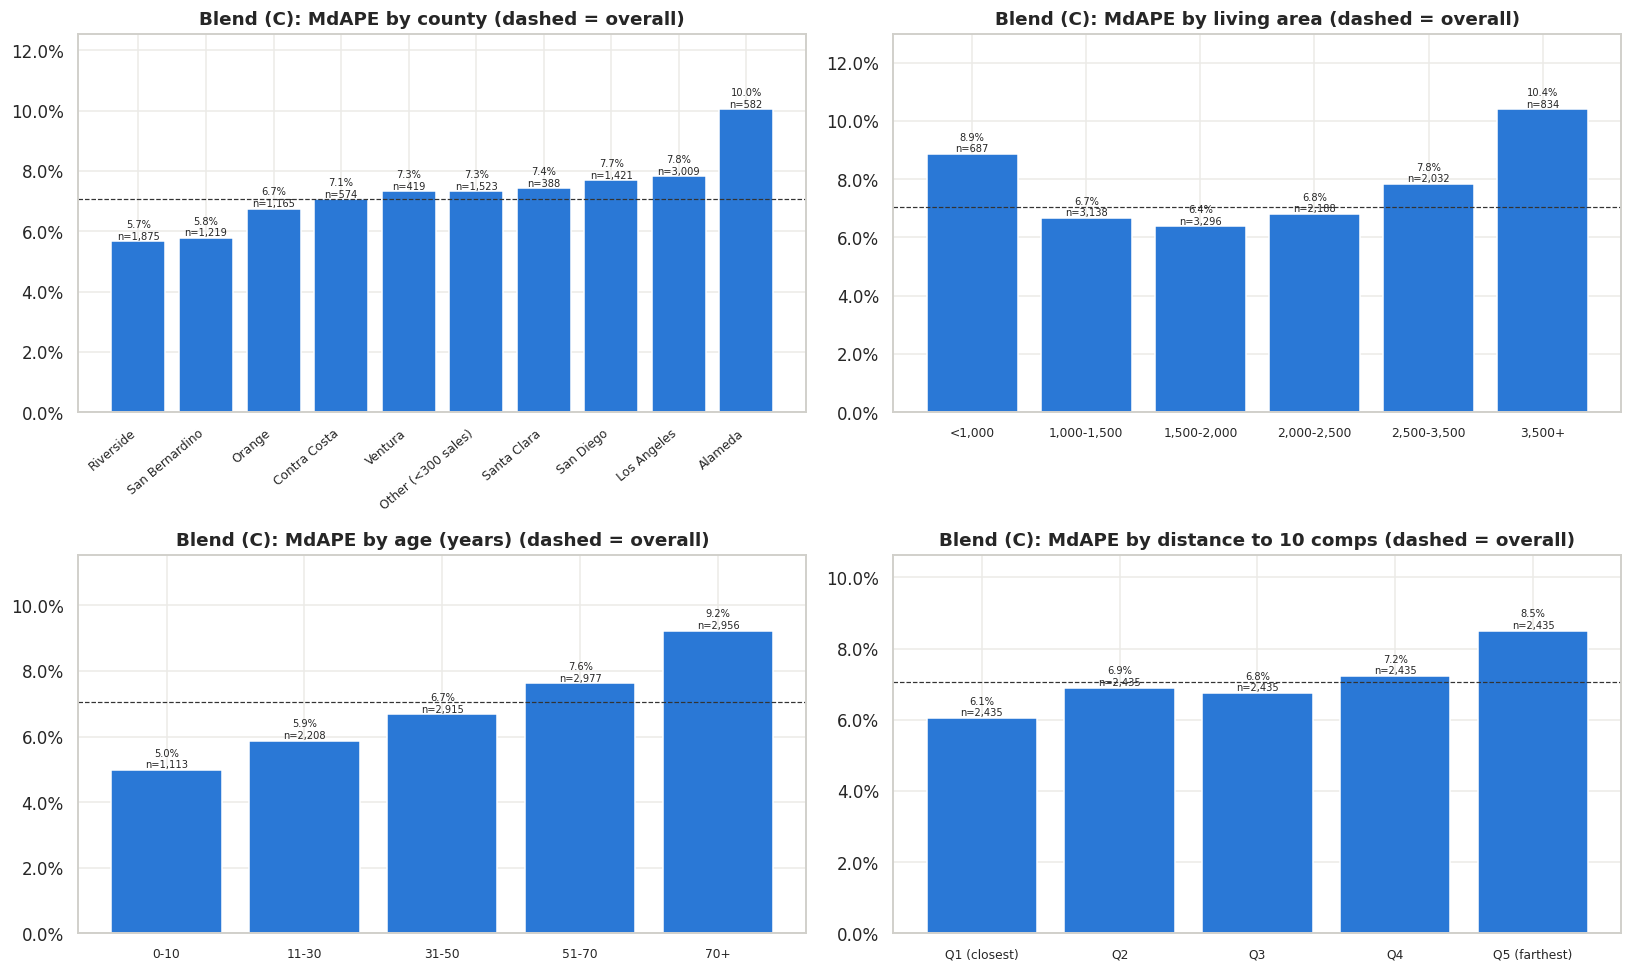

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(15, 9))
for a, sname in zip(axs.flat, ["County", "Living area", "Age (years)", "Distance to 10 comps"]):
    g = segments[(segments.segment_type == sname) & (segments.model == BEST)].set_index("segment")
    if sname == "County": g = g.sort_values("MdAPE")
    else: g = g.loc[[str(c_) for c_ in seg_def[sname].cat.categories]]
    a.bar(range(len(g)), g.MdAPE, color=BLUE)
    a.axhline(summary.loc[BEST, "MdAPE"], color="#333", lw=0.8, ls="--")
    a.set_xticks(range(len(g)), g.index, rotation=40 if sname == "County" else 0, ha="right" if sname == "County" else "center", fontsize=8)
    for i, (v, n) in enumerate(zip(g.MdAPE, g.n)): a.text(i, v, f"{v:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=6.5)
    a.set(title=f"{BEST}: MdAPE by {sname.lower()} (dashed = overall)"); a.yaxis.set_major_formatter(mtick.PercentFormatter())
    a.set_ylim(0, g.MdAPE.max() * 1.25)
fig.tight_layout(); save(fig, "error_by_segment"); plt.show()

## 7. Stability over time (validation months and April)

,2026-01,2026-02,2026-03,2026-04,mean,range,rank_each_month
Linear Regression,8.91,8.80,8.52,8.63,8.72,0.39,6/6/6/6
Decision Tree,9.05,9.18,9.03,8.98,9.06,0.20,7/7/7/7
Random Forest,7.58,7.60,7.37,7.58,7.53,0.22,5/5/5/5
Random Forest (C),7.57,7.56,7.32,7.53,7.50,0.25,4/4/4/4
XGBoost (C),7.17,7.13,6.92,7.16,7.10,0.25,3/1/3/3
LightGBM (C),7.11,7.20,6.84,7.12,7.07,0.36,2/3/2/2
Blend (C),7.10,7.14,6.83,7.06,7.03,0.31,1/2/1/1


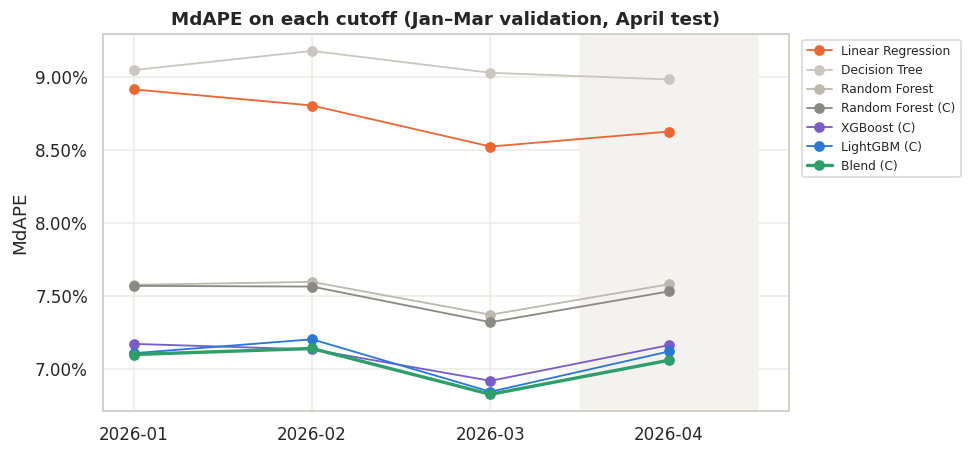

In [13]:
b6 = pd.read_csv(RES_DIR / "week6_backtest_mdape.csv", index_col=[0, 1])
b7 = pd.read_csv(RES_DIR / "week7_backtest_mdape.csv", index_col=0)
months = ["2026-01", "2026-02", "2026-03", TEST_MONTH]
stab = pd.DataFrame({
    "Linear Regression": b6.loc[("Linear Regression", "A. Old (Week 5)"), months],
    "Decision Tree": b6.loc[("Decision Tree", "A. Old (Week 5)"), months],
    "Random Forest": b6.loc[("Random Forest", "A. Old (Week 5)"), months],
    "Random Forest (C)": b7.loc["Random Forest", months],
    "XGBoost (C)": b7.loc["XGBoost", months],
    "LightGBM (C)": b7.loc["LightGBM", months],
    "Blend (C)": b7.loc["Blend", months]}).T
assert np.allclose(stab.loc["Random Forest (C)"], b6.loc[("Random Forest", "C. + school district"), months], atol=0.01)
stab["mean"], stab["range"] = stab[months].mean(axis=1), stab[months].max(axis=1) - stab[months].min(axis=1)
stab["rank_each_month"] = stab[months].rank().astype(int).astype(str).agg("/".join, axis=1)
display(stab.round(2))

fig, ax = plt.subplots(figsize=(9, 4.3))
pal = {"Linear Regression": ORANGE, "Decision Tree": "#c9c7c0", "Random Forest": "#bdb9b0", "Random Forest (C)": GREY,
       "XGBoost (C)": PURPLE, "LightGBM (C)": BLUE, "Blend (C)": GREEN}
for k in stab.index: ax.plot(months, stab.loc[k, months], marker="o", color=pal[k], lw=2.2 if k == BEST else 1.2, label=k)
ax.axvspan(2.5, 3.5, color="#f3f2ee"); ax.set(title="MdAPE on each cutoff (Jan–Mar validation, April test)", ylabel="MdAPE")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout(); save(fig, "stability_by_month"); plt.show()

## 8. Summary

In [14]:
s = summary
print(f"Best model (chosen on validation): {BEST}")
for k in KEYS:
    r = s.loc[k]
    print(f"  {k:20s} R2 {r.R2:.4f} | MAPE {r.MAPE:5.2f}% | MdAPE {r.MdAPE:5.2f}% ({r.MdAPE_ci_low:.2f}-{r.MdAPE_ci_high:.2f}) | within 10% {r.within_10pct:.1f}% | bias {r.median_bias_pct:+.2f}%")

Best model (chosen on validation): Blend (C)
  Blend (C)            R2 0.9220 | MAPE 10.24% | MdAPE  7.06% (6.90-7.23) | within 10% 63.6% | bias -0.57%
  Random Forest (C)    R2 0.9063 | MAPE 10.89% | MdAPE  7.53% (7.32-7.70) | within 10% 61.2% | bias -1.42%
  Linear Regression    R2 0.8886 | MAPE 12.02% | MdAPE  8.63% (8.43-8.80) | within 10% 56.2% | bias -0.61%
  Comp $/sqft × size   R2 0.8606 | MAPE 16.58% | MdAPE 12.71% (12.45-13.00) | within 10% 40.5% | bias -1.33%


**Findings**

**Overall (April 2026, 12,175 homes).** Best model, chosen on validation: the Week 7 **blend of LightGBM and XGBoost**: MdAPE **7.06%** (95% CI 6.90–7.23%), MAPE **10.24%**, R² **0.922** (log R² 0.949), 63.6% of homes within 10%, median bias −0.57%. The ranking is the same on every metric and every month: boosted models > Random Forest > Linear Regression > Decision Tree > comp-only references.

- **The differences are real where it matters.** Blend vs Week 6 Random Forest: −0.47 points (CI −0.62 to −0.31). Blend vs the Linear Regression baseline: −1.57 points. LightGBM vs XGBoost (−0.04) and the school-district layer for the Random Forest (−0.05) are within noise.
- **MAPE is about 1.45× MdAPE for every model** because errors have a long tail: the worst 5% of homes (missed by more than 30%) make up 22% of all percentage error; without the worst 10%, MAPE would be 7.5%. MdAPE is the better headline; MAPE tracks the tail.
- **R² in dollars is driven by expensive homes:** sales of $2.3M+ (top 10%) produce 68% of the squared dollar error. R² on homes below that is 0.886.

**Which price bands perform better**
- **Best: $450K–$910K** (deciles 2–5): MdAPE 5.5–5.9%, 72–75% of homes within 10%.
- **Worst: $2.3M+** (top decile): MdAPE 11.4%, only 45% within 10%. The cheapest decile (under $450K) is also weaker (MdAPE 7.2%, MAPE 12.8%).
- **Bias depends on how you band.** By actual price the model looks +1.6% too high on the cheapest fifth and −4.5% too low on the priciest fifth. By *predicted* price the bias is flat (−0.3% to −0.9% in every band), so most of that pattern is regression to the mean, not a systematic error. Accuracy, though, is genuinely worse at the top (MdAPE 10.0% in the top predicted-price fifth vs 5.4% in the second).

**Other segments (blend)**
- **Home age:** 5.0% MdAPE for homes 0–10 years old vs 9.2% for homes over 70 (condition and renovations are not in the data).
- **Size:** best at 1,500–2,000 sq ft (6.4%); worst at 3,500+ sq ft (10.4%) and under 1,000 sq ft (8.9%).
- **Comp distance:** 6.1% when the 10 comps are closest vs 8.5% when they are farthest; sparse neighbourhoods are harder.
- **County:** Riverside (5.7%) and San Bernardino (5.8%) best; Alameda worst (10.0%). Homes in unified school districts: 7.5% vs 6.1% in elementary + high areas.

**Takeaway for the team:** the model is reliable for typical homes ($450K–$1.1M, under 50 years old, with nearby comps) and should come with a wider confidence range for luxury, very old, very small or isolated homes. Week 9 (optional) can serve the saved LightGBM/XGBoost pipelines in a Streamlit app.